# German Credit Data Analysis

In this project I will explore the dataset and understand the main factors related to credit risk.

In [4]:
# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In this step I imported the libraries needed for data analysis `Pandas` is used to organize data `NumPy` is used for numerical operations and `Matplotlib` and `Seaborn` are used to create visualizations and understand patterns in the dataset.
تم استيراد المكتبات اللازمة لتنظيم البيانات وتحليلها وعرضها باستخدام الرسومات البيانية


In [3]:
# Load the dataset
df = pd.read_excel("german_credit_data.xlsx")

# Display the first five rows
df.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


The dataset was loaded successfully and I displayed the first five rows to get an initial look at the data.

تم تحميل البيانات وعرض أول خمسة صفوف للتعرّف على محتوياتها

In [5]:
# Check the number of rows and columns
df.shape 

(1000, 10)

The dataset contains 1,000 rows and 10 columns.

يعرض هذا الفحص عدد السجلات والأعمدة الموجودة في مجموعة البيانات

In [6]:
# Display the column names
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'SavingAccounts', 'CheckingAccount',
       'CreditAmount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

The dataset contains different features related to customers and their credit information.

تحتوي البيانات على مجموعة من الخصائص التي تصف العملاء ومعلوماتهم الائتمانية

In [7]:
# Check the data types of each column
df.dtypes

Age                 int64
Sex                object
Job                 int64
Housing            object
SavingAccounts     object
CheckingAccount    object
CreditAmount        int64
Duration            int64
Purpose            object
Risk               object
dtype: object

In this step I checked the data types of each column to understand how the data is stored This helps me identify which columns contain numerical values and which contain text so I can decide how to handle them during the analysis.

تم في هذه الخطوة فحص أنواع البيانات في كل عمود، لفهم طبيعة القيم وتحديد كيفية التعامل معها خلال التحليل

In [8]:
# Check for missing values in each column
df.isnull().sum()

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64

In this step I checked the dataset for missing values I found that `SavingAccounts` contains 183 missing values and `CheckingAccount` contains 394 missing values while the other columns have no missing values These missing values should be considered before continuing with the analysis.


In [9]:
# Display descriptive statistics for numerical columns
df.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In this step I used descriptive statistics to get a better understanding of the numerical data The results show that the average age is approximately 35.5 years while the average credit amount is about 3,271 The credit duration ranges from 4 to 72 months These statistics help me understand the distribution and range of the numerical variables before continuing the analysis.

تم في هذه الخطوة استخدام الإحصاءات الوصفية لفهم البيانات الرقمية والتعرّف على المتوسطات والمدى الذي تتوزع ضمنه القيم

In [10]:
# Count the customers in each risk category
df["Risk"].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In this step I counted the customers in each risk category The results show that 700 customers (70%) are classified as `good` while 300 customers (30%) are classified as `bad` This helps me understand the distribution of the target variable and compare the size of the two groups.

تم في هذه الخطوة حساب عدد العملاء في كل فئة من فئات المخاطرة الائتمانية لفهم توزيع الفئات ومقارنة أعدادها

In [13]:
# Calculate the percentage of each risk category
risk_percentages = df["Risk"].value_counts(normalize=True) * 100

risk_percentages

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64

In this step I calculated the percentage of customers in each risk category The results show that 70% of customers are classified as `good` and 30% as `bad` This gives me a clearer understanding of the distribution of the risk categories.


In [12]:
# Show a summary of the text columns
df.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In this step I summarized the non-numerical columns to identify the number of different categories and the most frequent value in each column The results show that `male` is the most frequent value in `Sex` `own` in `Housing` and `car` in `Purpose` I also noticed that `SavingAccounts` and `CheckingAccount` contain fewer non-missing values than the other columns.

تم في هذه الخطوة تلخيص الأعمدة غير الرقمية لمعرفة عدد الفئات المختلفة والفئة الأكثر تكرارًا كما لاحظت وجود قيم ناقصة في عمودي 
`SavingAccounts` و`CheckingAccount`

In [14]:
# Check the categories in the Housing column
df["Housing"].value_counts()

Housing
own     713
rent    179
free    108
Name: count, dtype: int64

In this step I checked the distribution of the categories in the `Housing` column The results show that 713 customers have their own housing 179 rent their housing and 108 are in the free housing category This helps me understand the different housing categories in the dataset

تم في هذه الخطوة فحص توزيع فئات السكن، وتبيّن أن فئة السكن المملوك هي الأكثر تكرارًا بين العملاء

In [15]:
# Check the distribution of loan purposes
df["Purpose"].value_counts()

Purpose
car                    337
radio/TV               280
furniture/equipment    181
business                97
education               59
repairs                 22
domestic appliances     12
vacation/others         12
Name: count, dtype: int64

In this step I checked the distribution of loan purposes The most common purpose is `car` with 337 customers followed by `radio/TV` with 280 customers The least common purposes are `domestic appliances` and `vacation/others` with 12 customers each.

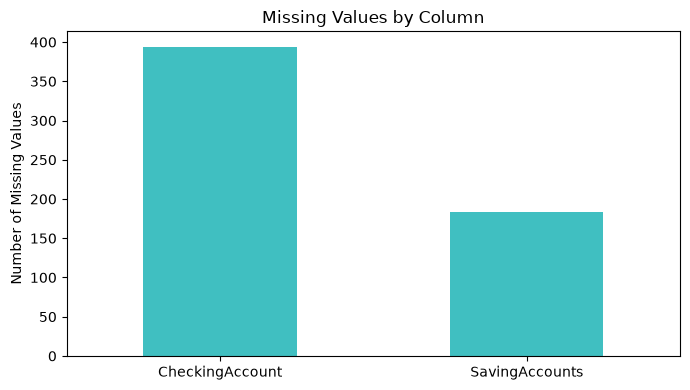

In [16]:
# Visualize missing values in the dataset

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing_counts.plot(kind="bar", color="#40BFC1")

plt.title("Missing Values by Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

The plot shows the number of missing values in each column `CheckingAccount` has 394 missing values while `SavingAccounts` has 183 These missing values should be considered when preparing the data for further analysis.

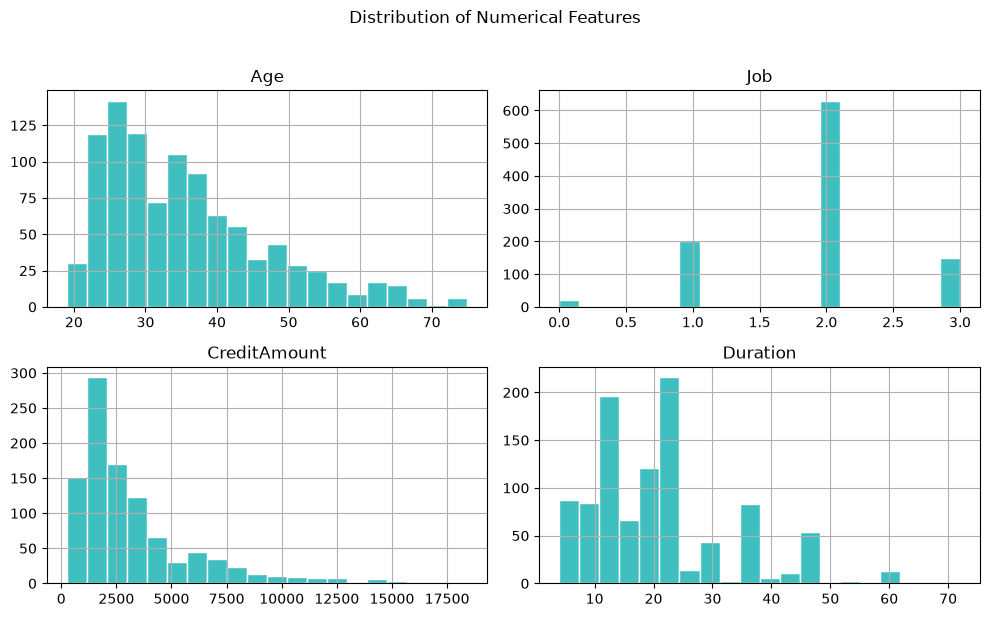

In [17]:
# Visualize the distribution of numerical features

numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

df[numeric_cols].hist(
    figsize=(10, 6),
    bins=20,
    color="#40BFC1",
    edgecolor="white"
)

plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

The histograms show the distribution of the numerical features Most customers are within the middle age ranges while `CreditAmount` and `Duration` show more values at the lower end and fewer at the higher end.

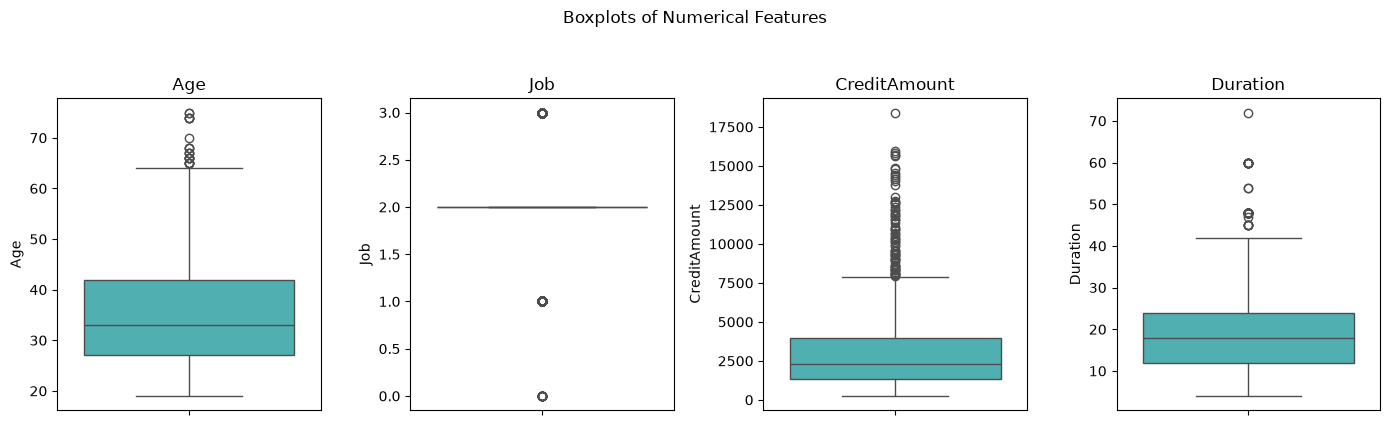

In [18]:
# Visualize numerical features using boxplots

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="#40BFC1")
    ax.set_title(col)

plt.suptitle("Boxplots of Numerical Features", y=1.05)
plt.tight_layout()
plt.show()

The boxplots help identify the spread of numerical values and potential outliers `CreditAmount` and `Duration` may show high-value outliers indicating that some customers have larger loans or longer repayment periods than most others.

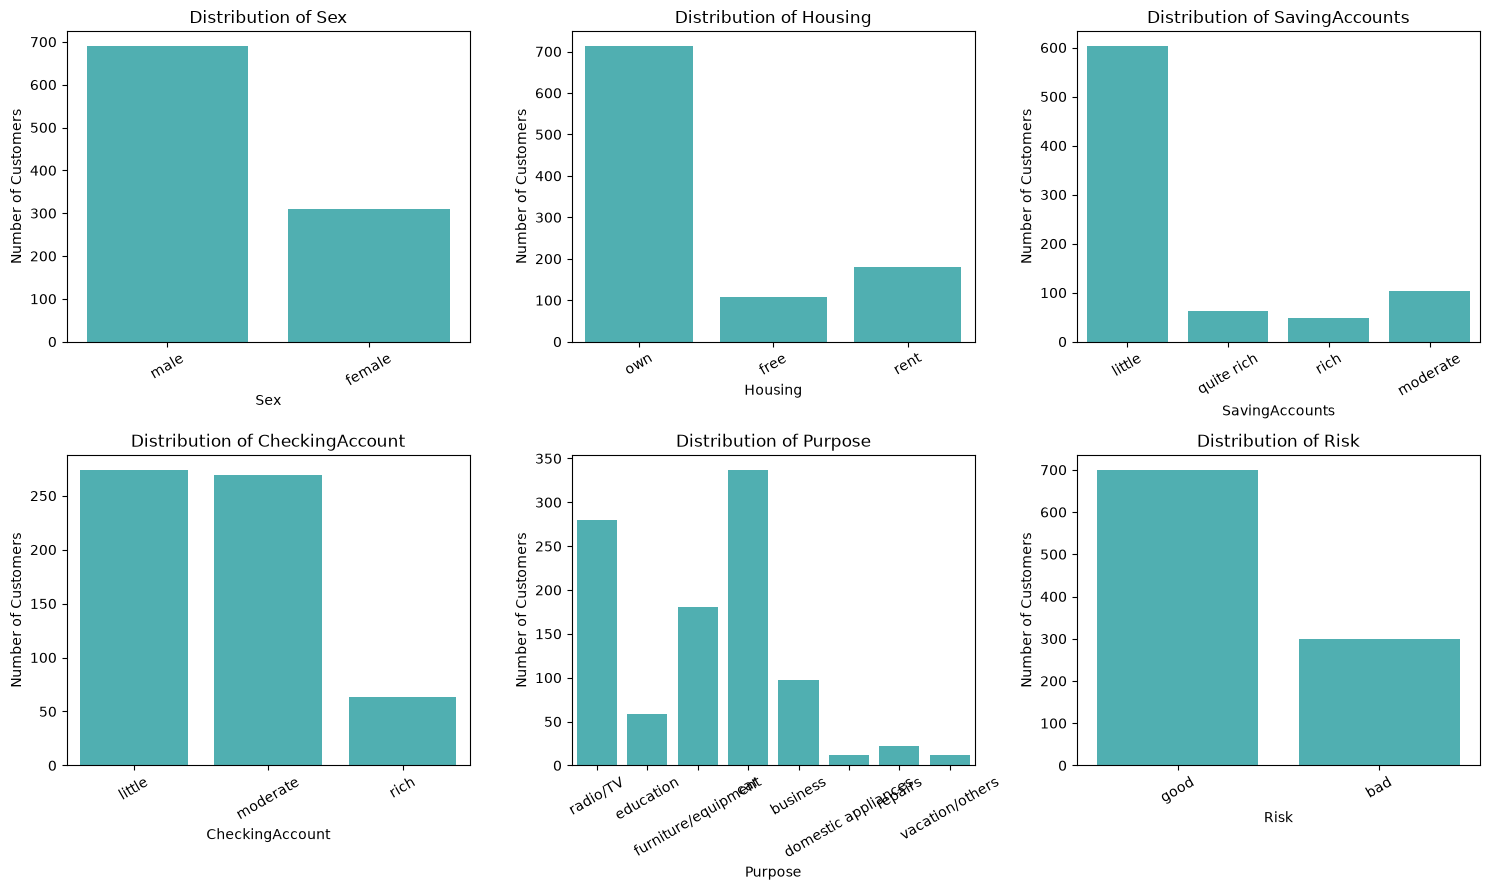

In [19]:
# Visualize the distribution of categorical features

categorical_cols = ["Sex", "Housing", "SavingAccounts",
                    "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=df, x=col, ax=ax, color="#40BFC1")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Customers")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

The count plots show the distribution of customers across categorical features The plots help compare categories in terms of frequency and show which categories are more common Missing values are not displayed as separate categories in these plots.

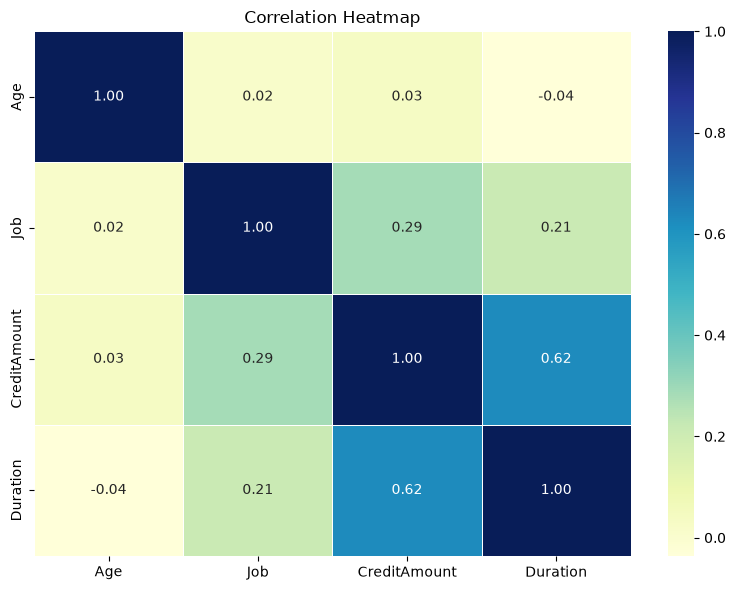

In [20]:
# Visualize correlations between numerical features

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

The correlation heatmap shows the relationships between numerical features Values closer to 1 indicate a positive relationship values closer to -1 indicate a negative relationship and values near 0 indicate a weak linear relationship
 Correlation does not necessarily mean causation.

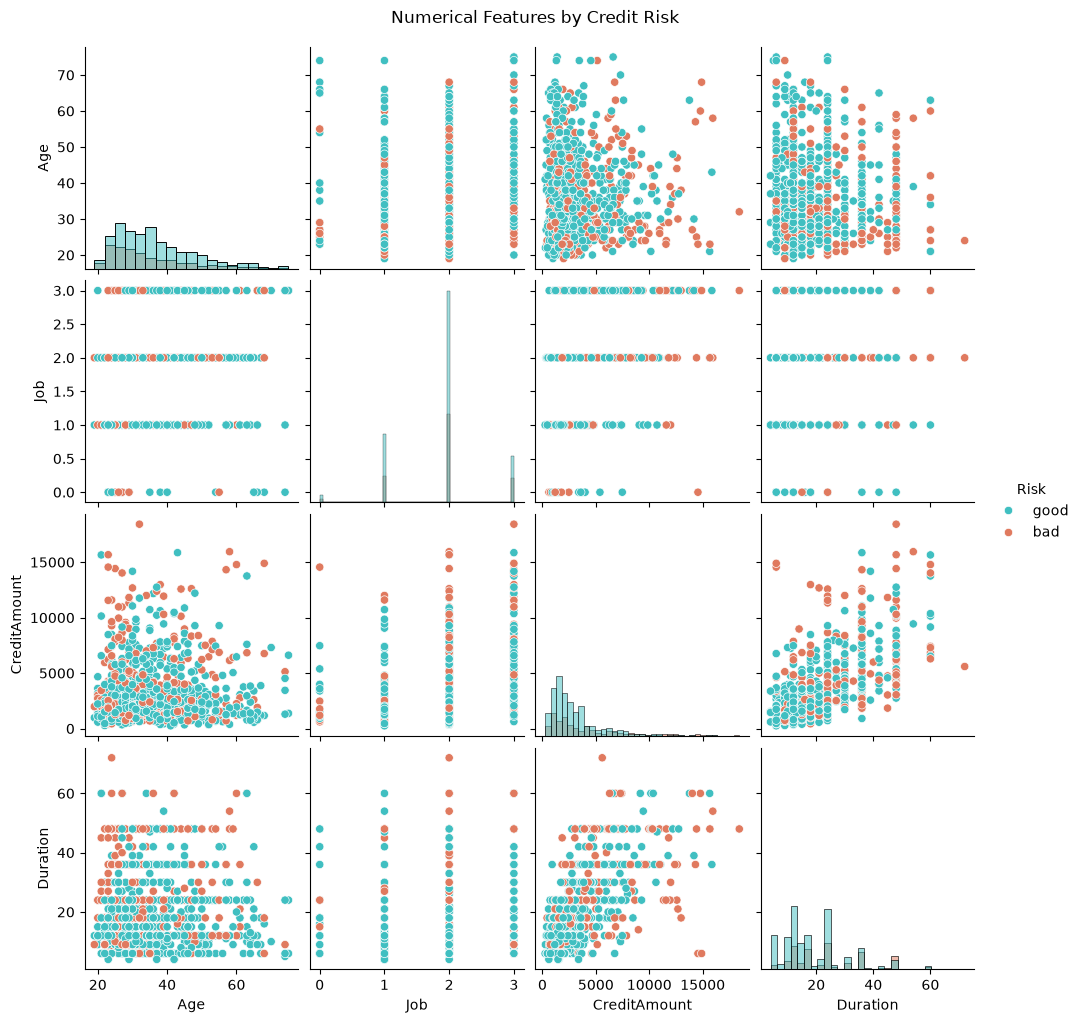

In [21]:
# Compare numerical features according to credit risk

sns.pairplot(
    df,
    vars=numeric_cols,
    hue="Risk",
    palette={"good": "#40BFC1", "bad": "#E07A5F"},
    diag_kind="hist"
)

plt.suptitle("Numerical Features by Credit Risk", y=1.02)
plt.show()

The pairplot shows the relationships between numerical features with different colors representing the two risk categories It helps explore whether customers classified as `good` and `bad` show different patterns in age job credit amount and credit duration.

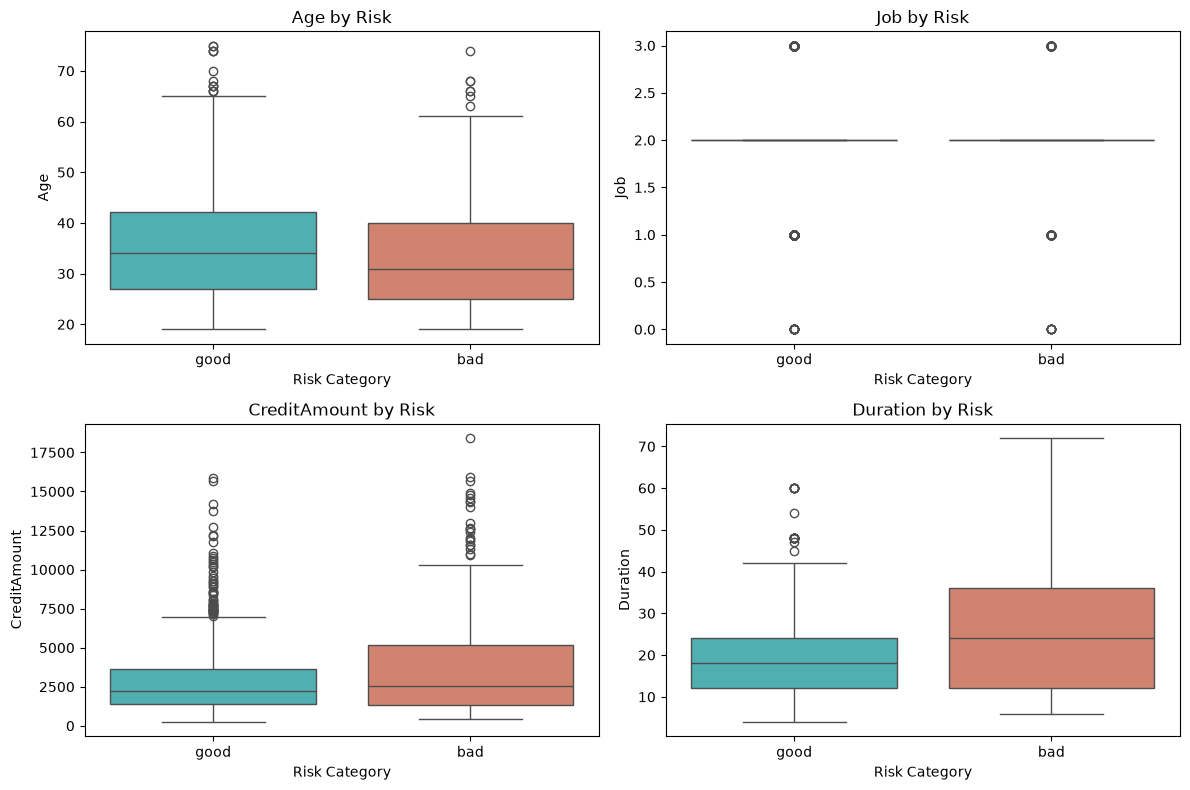

In [22]:
# Compare numerical features across risk categories

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=df,
        x="Risk",
        y=col,
        hue="Risk",
        palette={"good": "#40BFC1", "bad": "#E07A5F"},
        legend=False,
        ax=ax
    )
    ax.set_title(f"{col} by Risk")
    ax.set_xlabel("Risk Category")

plt.tight_layout()
plt.show()

These boxplots compare the numerical features of customers in the `good` and `bad` risk categories They help identify differences in the distributions of age job credit amount and credit duration between the two groups The plots show patterns in the data but do not prove that a feature causes a particular risk category.

In [23]:
# Handle missing values

df_clean = df.copy()

df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

# Check if any missing values remain
df_clean.isnull().sum()

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64

In this step I replaced the missing values in `SavingAccounts` and `CheckingAccount` with `none` The results confirm that no missing values remain in the dataset All 1,000 rows were kept for further analysis.

In [24]:
# Convert categorical columns into numerical values

from sklearn.preprocessing import LabelEncoder

df_encoded = df_clean.copy()

categorical_cols = [
    "Sex", "Housing", "SavingAccounts",
    "CheckingAccount", "Purpose", "Risk"
]

for col in categorical_cols:
    encoder = LabelEncoder()
    df_encoded[col] = encoder.fit_transform(df_clean[col])

df_encoded.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,1,2,1,2,0,1169,6,5,1
1,22,0,2,1,0,1,5951,48,5,0
2,49,1,1,1,0,2,2096,12,3,1
3,45,1,2,0,0,0,7882,42,4,1
4,53,1,2,0,0,0,4870,24,1,0


In this step I converted the categorical columns into numerical values using `LabelEncoder` I created a new DataFrame called `df_encoded` to preserve the cleaned dataset Each category was assigned a numerical label making the data suitable for further analysis and certain machine learning methods.

In [30]:

from sklearn.preprocessing import StandardScaler

scaled_cols = ["Age", "Job", "CreditAmount", "Duration"]

scaler = StandardScaler()
df_scaled = df_encoded.copy()

df_scaled[scaled_cols] = scaler.fit_transform(df_scaled[scaled_cols])

df_scaled.head()


,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,2.766456,1,0.146949,1,2,0,-0.745131,-1.236478,5,1
1,-1.191404,0,0.146949,1,0,1,0.949817,2.248194,5,0
2,1.183312,1,-1.383771,1,0,2,-0.416562,-0.738668,3,1
3,0.831502,1,0.146949,0,0,0,1.634247,1.750384,4,1
4,1.535122,1,0.146949,0,0,0,0.566664,0.256953,1,0


In this step I applied `StandardScaler` to the `Age` job `CreditAmount` and `Duration` columns This transformed the selected features to a common scale with values centered around zero I stored the scaled data in a separate DataFrame called `df_scaled` keeping the encoded data unchanged.

In [31]:

print("Before Scaling:")
display(df_encoded[["Age", "Job", "CreditAmount", "Duration"]].head(3))

print("After Scaling:")
display(df_scaled[["Age", "Job", "CreditAmount", "Duration"]].head(3))


Before Scaling:


,Age,Job,CreditAmount,Duration
0,67,2,1169,6
1,22,2,5951,48
2,49,1,2096,12


After Scaling:


,Age,Job,CreditAmount,Duration
0,2.766456,0.146949,-0.745131,-1.236478
1,-1.191404,0.146949,0.949817,2.248194
2,1.183312,-1.383771,-0.416562,-0.738668


In [26]:

# Separate the features from the target variable

X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (1000, 9)
Target shape: (1000,)


In this step I separated the dataset into features (`X`) and the target variable (`y`) The features contain 9 columns used as input variables while the target variable contains the `Risk` category that we aim to predict Both contain 1,000 records corresponding to the 1,000 customers in the dataset.

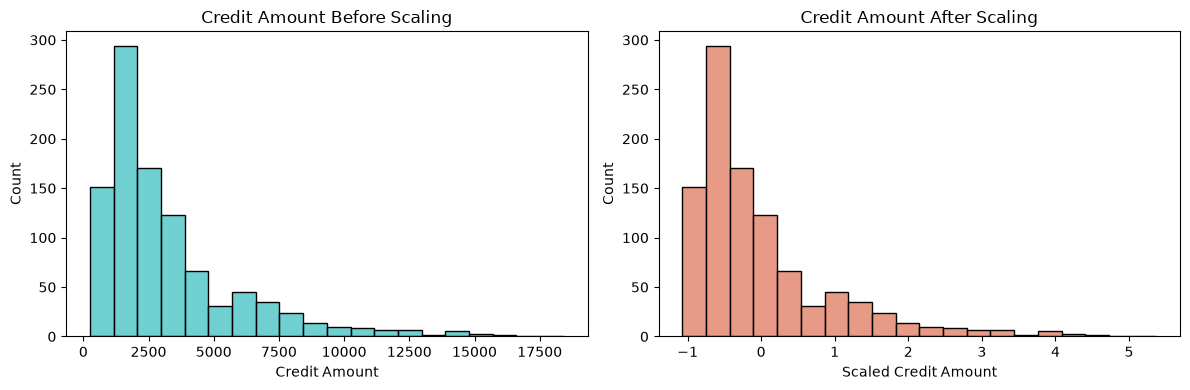

In [27]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_encoded["CreditAmount"], bins=20, color="#40BFC1", ax=axes[0])
axes[0].set_title("Credit Amount Before Scaling")
axes[0].set_xlabel("Credit Amount")

sns.histplot(df_scaled["CreditAmount"], bins=20, color="#E07A5F", ax=axes[1])
axes[1].set_title("Credit Amount After Scaling")
axes[1].set_xlabel("Scaled Credit Amount")

plt.tight_layout()
plt.show()


The histograms compare the distribution of `CreditAmount` before and after scaling Before scaling the values are measured in their original monetary units After applying `StandardScaler` the values are centered around zero and expressed on a standardized scale The overall distribution pattern remains similar but the scale of the horizontal axis changes.

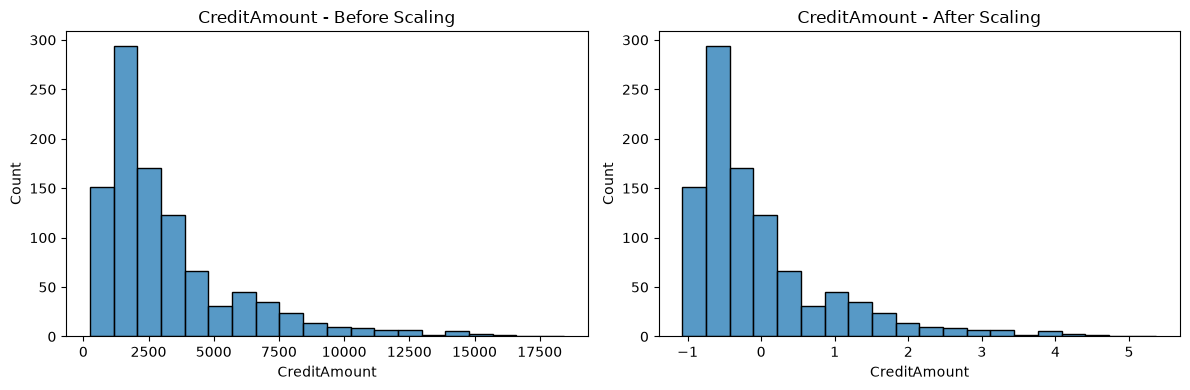

In [33]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0])
axes[0].set_title("CreditAmount - Before Scaling")

sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1])
axes[1].set_title("CreditAmount - After Scaling")

plt.tight_layout()
plt.show()


In [28]:

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(f_classif, k="all")
scores = selector.fit(X, y).scores_

feature_ranking = pd.DataFrame({
    "Feature": X.columns,
    "Score": scores
})

feature_ranking = feature_ranking.sort_values("Score", ascending=False)

feature_ranking


,Feature,Score
5,CheckingAccount,111.721482
7,Duration,48.333790
4,SavingAccounts,33.948465
6,CreditAmount,24.482366
0,Age,8.356995
1,Sex,5.720350
8,Purpose,3.745234
2,Job,1.070584
3,Housing,0.372463


The feature selection results show that `CheckingAccount` has the highest F-score followed by `Duration` and `SavingAccounts` In contrast`Housing` has the lowest score These results indicate that `CheckingAccount` shows the strongest differences between the `good` and `bad` risk categories according to the `f_classif` test This ranking helps identify which features may be more relevant for further analysis.

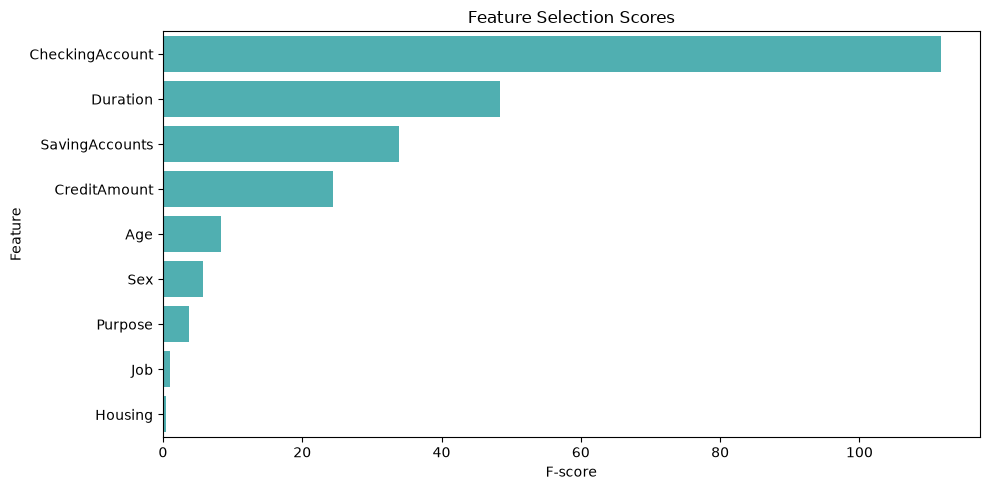

In [29]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_ranking,
    x="Score",
    y="Feature",
    color="#40BFC1"
)

plt.title("Feature Selection Scores")
plt.xlabel("F-score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


The bar chart compares the F-scores of the features in relation to the target variable `Risk`. `CheckingAccount` has the highest score followed by `Duration` and `SavingAccounts` while `Housing` has the lowest score These scores indicate differences between the risk categories according to the statistical test but they do not establish causation.